In [2]:
pip install ucimlrepo

In [3]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
online_retail = fetch_ucirepo(id=352)

# data (as pandas dataframes)
x = online_retail.data.features
y = online_retail.data.targets

# metadata
print(online_retail.metadata)

# variable information
print(online_retail.variables)

{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
print("Features type:", type(x))
print("Features shape:", x.shape)

print("\nTargets:", y)

print("\nFeatures columns:")
print(x.columns.tolist())

display(x.head())

Features type: <class 'pandas.core.frame.DataFrame'>
Features shape: (541909, 6)

Targets: None

Features columns:
['Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [6]:
print(y)

None


In [7]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


In [8]:
x.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [9]:
x.isnull().sum()

,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [10]:
customer_line_items = x['CustomerID'].value_counts()
top_10_customers = customer_line_items.head(10)

display(top_10_customers)

,count
CustomerID,
17841.0,7983
14911.0,5903
14096.0,5128
12748.0,4642
14606.0,2782
15311.0,2491
14646.0,2085
13089.0,1857
13263.0,1677


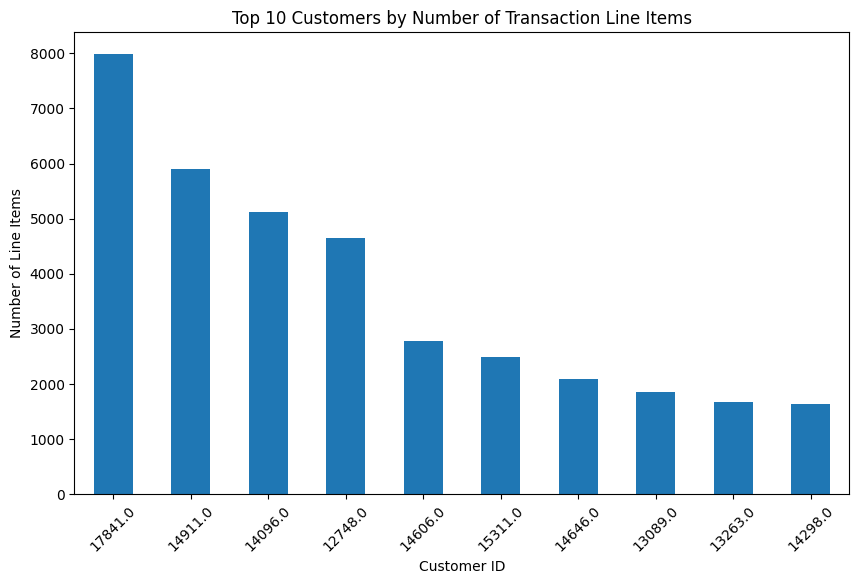

In [11]:
plt.figure(figsize=(10, 6))

top_10_customers.plot(kind='bar')

plt.title('Top 10 Customers by Number of Transaction Line Items')
plt.xlabel('Customer ID')
plt.ylabel('Number of Line Items')
plt.xticks(rotation=45)

plt.show()

In [12]:
print("Unique Customers:", x['CustomerID'].nunique())

print("Missing Customer IDs:", x['CustomerID'].isna().sum())

Unique Customers: 4372
Missing Customer IDs: 135080


### Initial Customer Insights

- Total records: **541,909**.
- Unique customers: **4,372**.
- Missing CustomerIDs: **135,080 (24.93%)**.
- Available CustomerIDs: **406,829 (75.07%)**.
- Customer line-item distribution is highly right-skewed, indicating significant differences in customer activity.

**Note:** Missing CustomerIDs will be investigated before making any removal decisions.

In [13]:
x['LineTotal'] = x['Quantity'] * x['UnitPrice']

/tmp/ipykernel_867/1116563915.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  x['LineTotal'] = x['Quantity'] * x['UnitPrice']


In [14]:
customer_with_most_payment = (
    x.groupby('CustomerID')['LineTotal']
    .sum()
    .sort_values(ascending=False)
)

top_10_spending_customers = customer_with_most_payment.head(10)

display(top_10_spending_customers)

,LineTotal
CustomerID,
14646.0,279489.02
18102.0,256438.49
17450.0,187482.17
14911.0,132572.62
12415.0,123725.45
14156.0,113384.14
17511.0,88125.38
16684.0,65892.08
13694.0,62653.10


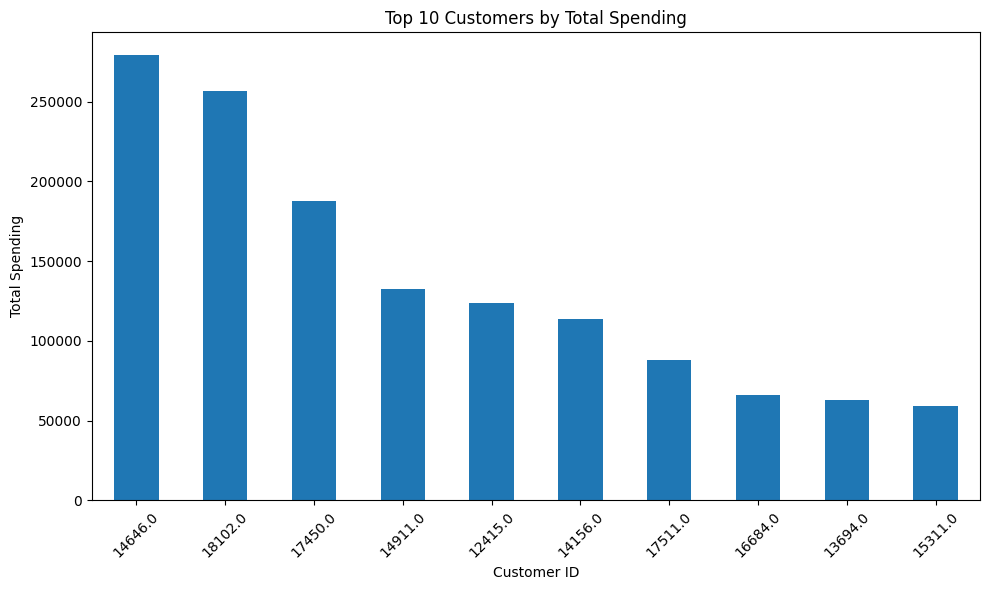

In [15]:
plt.figure(figsize=(10, 6))

top_10_spending_customers.plot(kind='bar')

plt.title('Top 10 Customers by Total Spending')
plt.xlabel('Customer ID')
plt.ylabel('Total Spending')

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Top Spending Customers

- Customer **14646** recorded the highest net spending, totaling **279,489.02**.
- Customer **18102** ranked second with **256,438.49**.
- Customer **17450** ranked third with **187,482.17**.
- Customer spending varies considerably across the top 10 customers.
- **Customers with the highest number of transaction line items are not necessarily the highest spenders.** Customer activity and spending value represent two different aspects of purchasing behavior.

*Note: Spending values are calculated as Quantity × UnitPrice, including negative quantities. They represent net line totals before further investigation of cancellations and returns.*

In [16]:
product_data = x[
    x['Description'].notna() &
    (x['Quantity'] > 0)
].copy()

In [17]:
top_selling_products = (
    product_data.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_selling_products)

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS,55047
JUMBO BAG RED RETROSPOT,48478
WHITE HANGING HEART T-LIGHT HOLDER,37895
POPCORN HOLDER,36761
ASSORTED COLOUR BIRD ORNAMENT,36461
PACK OF 72 RETROSPOT CAKE CASES,36419
RABBIT NIGHT LIGHT,30788


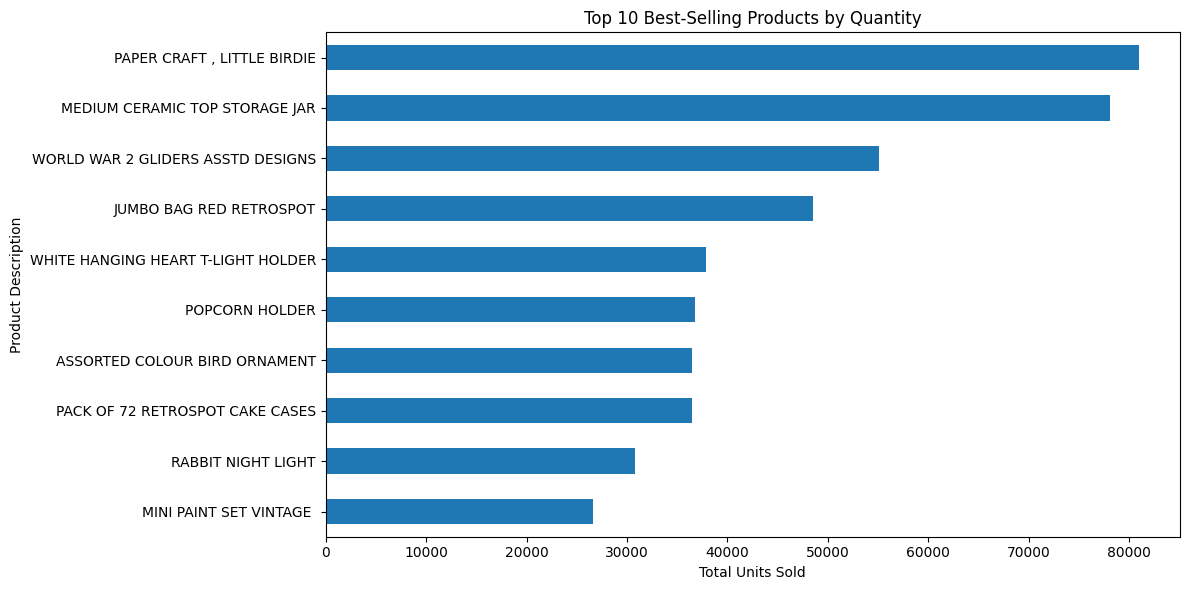

In [18]:
plt.figure(figsize=(12, 6))

top_selling_products.sort_values().plot(kind='barh')

plt.title('Top 10 Best-Selling Products by Quantity')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

In [19]:
product_revenue = (
    product_data.groupby('Description')['LineTotal']
    .sum()
    .sort_values(ascending=False)
)

top_10_revenue_products = product_revenue.head(10)

display(top_10_revenue_products)

,LineTotal
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174484.74
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106292.77
PARTY BUNTING,99504.33
JUMBO BAG RED RETROSPOT,94340.05
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
Manual,78112.82
POSTAGE,78101.88


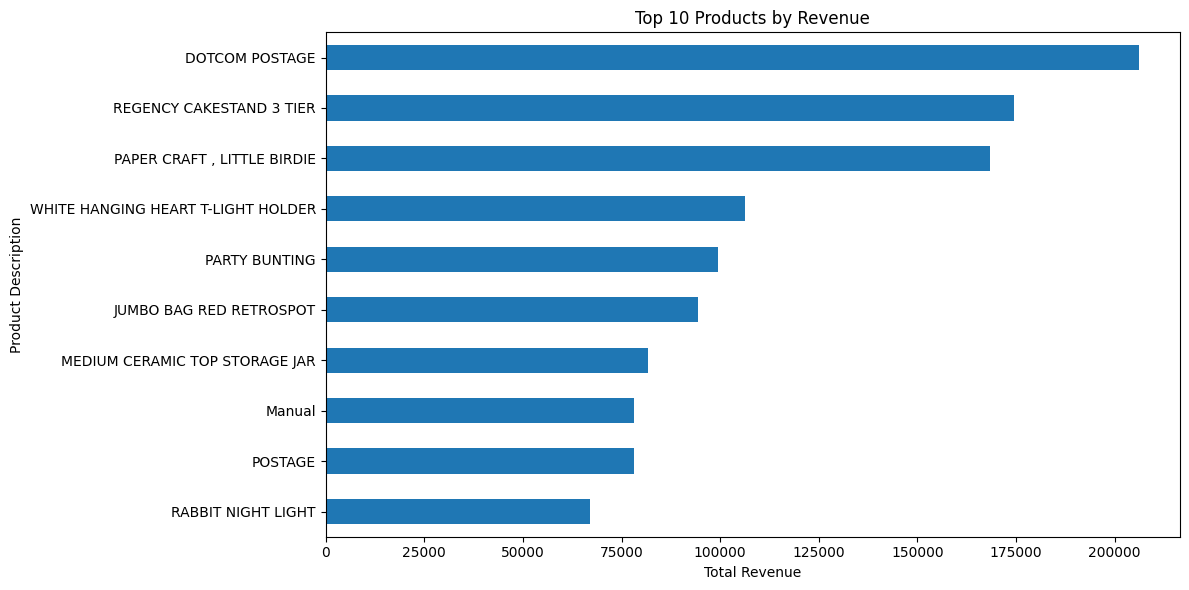

In [20]:
plt.figure(figsize=(12, 6))

top_10_revenue_products.sort_values().plot(kind='barh')

plt.title('Top 10 Products by Revenue')
plt.xlabel('Total Revenue')
plt.ylabel('Product Description')

plt.tight_layout()
plt.show()

### Product Sales and Revenue Insights

- `PAPER CRAFT, LITTLE BIRDIE` ranks first in sales quantity (**80,995 units**) but third in revenue (**168,469.60**).
- `DOTCOM POSTAGE` generates the highest recorded revenue (**206,248.77**), although it represents a postage-related charge rather than a conventional product.
- `REGENCY CAKESTAND 3 TIER` ranks second in revenue (**174,484.74**) despite not appearing among the top 10 products by quantity.
- The difference between quantity and revenue rankings highlights that sales volume alone does not determine revenue performance.

**Note:** Revenue is calculated using positive-quantity rows only. The analysis is grouped by product description, and includes service-related entries such as postage.

In [21]:
product_revenue = (
    product_data.groupby('Description')['LineTotal']
    .sum()
    .sort_values(ascending=False)
)

top_10_revenue_products = product_revenue.tail(10)

display(top_10_revenue_products)

,LineTotal
Description,
amazon adjust,0.00
rcvd be air temp fix for dotcom sit,0.00
wrongly coded 23343,0.00
TRAVEL CARD WALLET DOTCOMGIFTSHOP,0.00
website fixed,0.00
wrongly coded 20713,0.00
wrongly marked 23343,0.00
wrongly marked,0.00
wrongly sold (22719) barcode,0.00


In [22]:
low_selling_products = (
    product_data.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=True)
)

bottom_30_products = low_selling_products.head(30)

display(bottom_30_products)

,Quantity
Description,
for online retail orders,1
*Boombox Ipod Classic,1
GREEN PENDANT SHELL NECKLACE,1
ORANGE FELT VASE + FLOWERS,1
WIRE FLOWER T-LIGHT HOLDER,1
GARDENERS KNEELING PAD,1
JARDIN ETCHED GLASS BUTTER DISH,1
PINK POLKADOT KIDS BAG,1
NECKLACE+BRACELET SET PINK DAISY,1


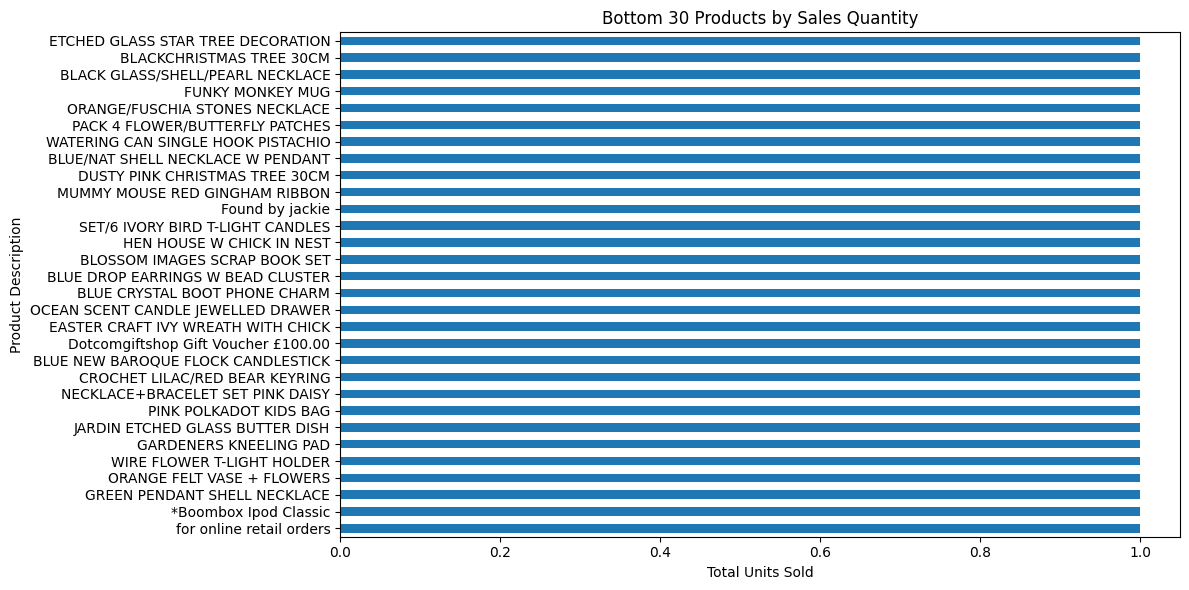

In [23]:
plt.figure(figsize=(12, 6))

bottom_30_products.sort_values(ascending=False).plot(kind='barh')

plt.title('Bottom 30 Products by Sales Quantity')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

In [24]:
product_sales = (
    product_data.groupby('Description')['Quantity']
    .sum()
)

print("Total unique products:", product_sales.count())
print("\nSales quantity statistics:")
display(product_sales.describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
))

print("\nNumber of products by sales quantity:")
display(product_sales.value_counts().head(10))

Total unique products: 4077

Sales quantity statistics:


,Quantity
count,4077.000000
mean,1380.533235
std,3453.951223
min,1.000000
10%,10.000000
25%,54.000000
50%,349.000000
75%,1361.000000
90%,3377.600000
max,80995.000000



Number of products by sales quantity:


,count
Quantity,
1,69
2,69
4,47
3,46
12,45
5,42
8,37
10,36
6,35


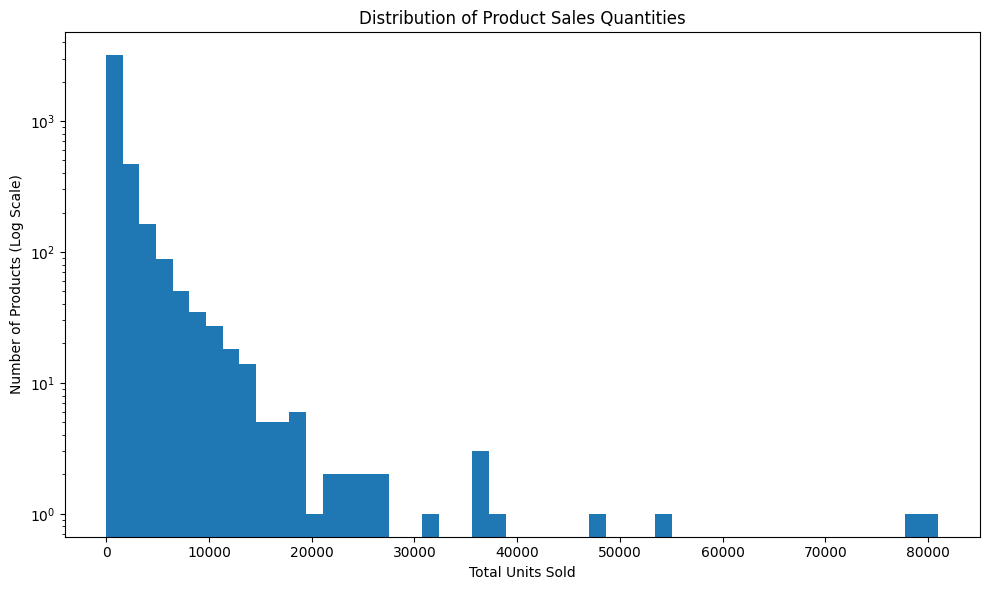

In [25]:
plt.figure(figsize=(10, 6))

plt.hist(product_sales, bins=50, log=True)

plt.title('Distribution of Product Sales Quantities')
plt.xlabel('Total Units Sold')
plt.ylabel('Number of Products (Log Scale)')
plt.tight_layout()
plt.show()

In [26]:
low_sales_threshold = product_sales.quantile(0.10)

low_selling_products = (
    product_sales[product_sales <= low_sales_threshold]
    .sort_values()
)

print("Low sales threshold:", low_sales_threshold)
print("Number of low-selling products:", len(low_selling_products))
print("Percentage of products:",
      round(len(low_selling_products) / len(product_sales) * 100, 2), "%")

display(low_selling_products.head(20))

Low sales threshold: 10.0
Number of low-selling products: 424
Percentage of products: 10.4 %


,Quantity
Description,
I LOVE LONDON MINI RUCKSACK,1
*Boombox Ipod Classic,1
Amazon Adjustment,1
for online retail orders,1
WATERING CAN SINGLE HOOK PISTACHIO,1
BAROQUE BUTTERFLY EARRINGS MONTANA,1
TINY CRYSTAL BRACELET RED,1
VINTAGE BEAD PINK JEWEL STAND,1
BLACK GLASS/SHELL/PEARL NECKLACE,1


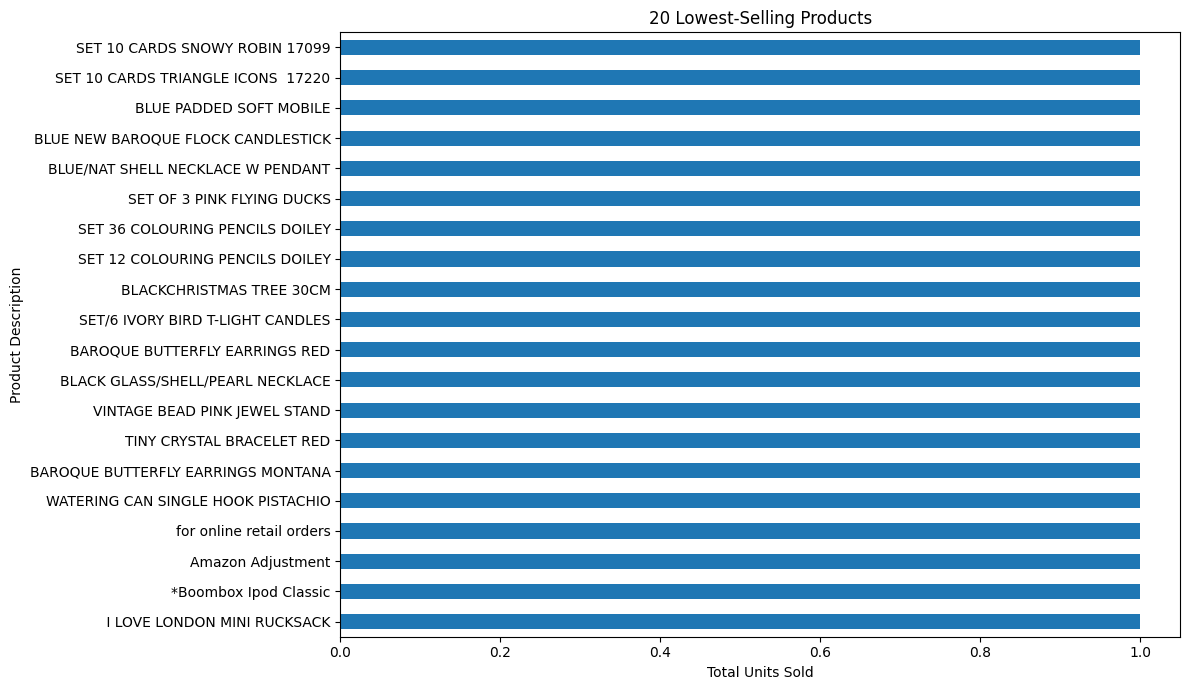

In [27]:
plt.figure(figsize=(12, 7))

low_selling_products.head(20).sort_values().plot(kind='barh')

plt.title('20 Lowest-Selling Products')
plt.xlabel('Total Units Sold')
plt.ylabel('Product Description')
plt.tight_layout()
plt.show()

### Low-Selling Products Insights

- Out of 4,077 unique product descriptions, 424 products (10.4%) recorded sales of 10 units or fewer.
- The 10th percentile of product sales quantity is 10 units.
- 69 products recorded only one unit sold.
- Low sales volume does not necessarily indicate poor product performance, as factors such as pricing, seasonality, and product availability have not been investigated.

**Note:** The low-sales threshold is an exploratory statistical criterion, not a definitive business classification.

In [28]:
x['InvoiceDate_dt'] = pd.to_datetime(
    x['InvoiceDate'],
    errors='coerce'
)

print("Date range:")
print("Start:", x['InvoiceDate_dt'].min())
print("End:", x['InvoiceDate_dt'].max())

print("\nMissing dates after conversion:")
print(x['InvoiceDate_dt'].isna().sum())

print("\nData type:")
print(x['InvoiceDate_dt'].dtype)

Date range:
Start: 2010-12-01 08:26:00
End: 2011-12-09 12:50:00

Missing dates after conversion:
0

Data type:
datetime64[ns]


In [29]:
monthly_revenue = (
    x.groupby(x['InvoiceDate_dt'].dt.to_period('M'))['LineTotal']
    .sum()
)

display(monthly_revenue.to_frame())

,LineTotal
InvoiceDate_dt,
2010-12,748957.020
2011-01,560000.260
2011-02,498062.650
2011-03,683267.080
2011-04,493207.121
2011-05,723333.510
2011-06,691123.120
2011-07,681300.111
2011-08,682680.510


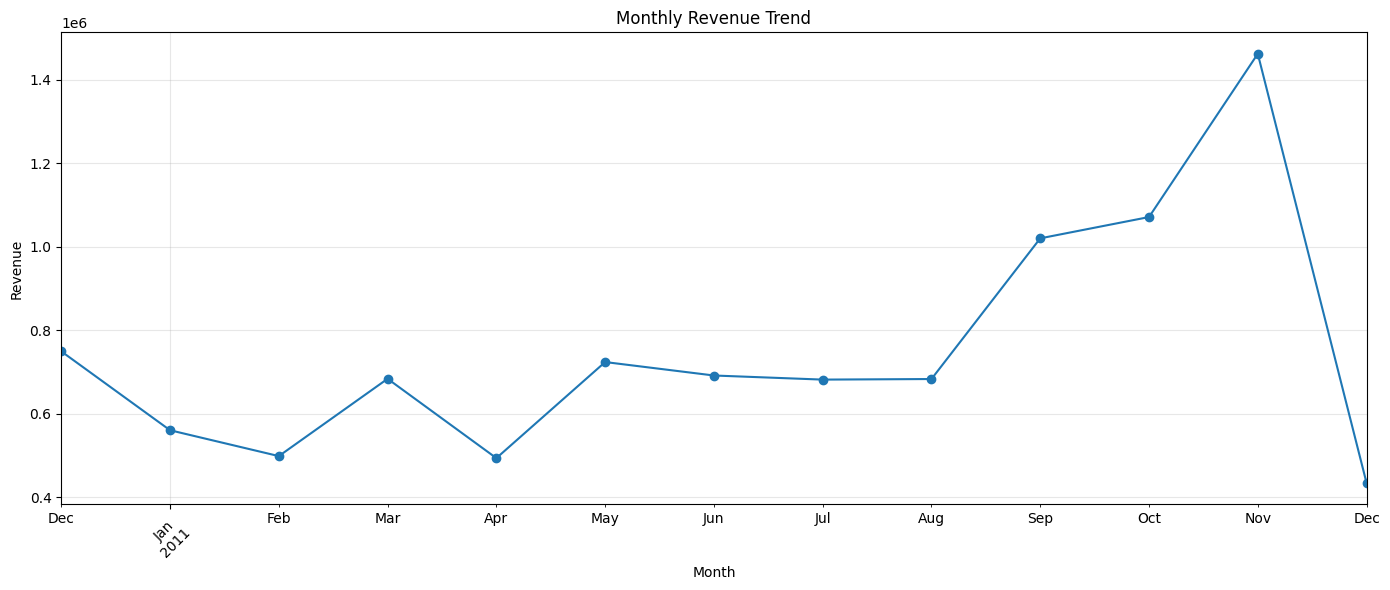

In [30]:
plt.figure(figsize=(14, 6))

monthly_revenue.plot(kind='line', marker='o')

plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Revenue Insights

- Revenue fluctuated during the first four months of 2011.
- Monthly revenue remained relatively stable between May and August.
- A significant increase occurred from September to November.
- November recorded the highest monthly revenue, reaching approximately 1.46 million.
- December 2011 shows a lower value because the dataset only covers the first nine days of the month.

**Note:** Monthly values represent the sum of recorded line totals, including negative quantities. Therefore, they should not be interpreted as confirmed accounting revenue.

In [31]:
monthly_quantity = (
    x.groupby(x['InvoiceDate_dt'].dt.to_period('M'))['Quantity']
    .sum()
)

display(monthly_quantity.to_frame())

,Quantity
InvoiceDate_dt,
2010-12,342228
2011-01,308966
2011-02,277989
2011-03,351872
2011-04,289098
2011-05,380391
2011-06,341623
2011-07,391116
2011-08,406199


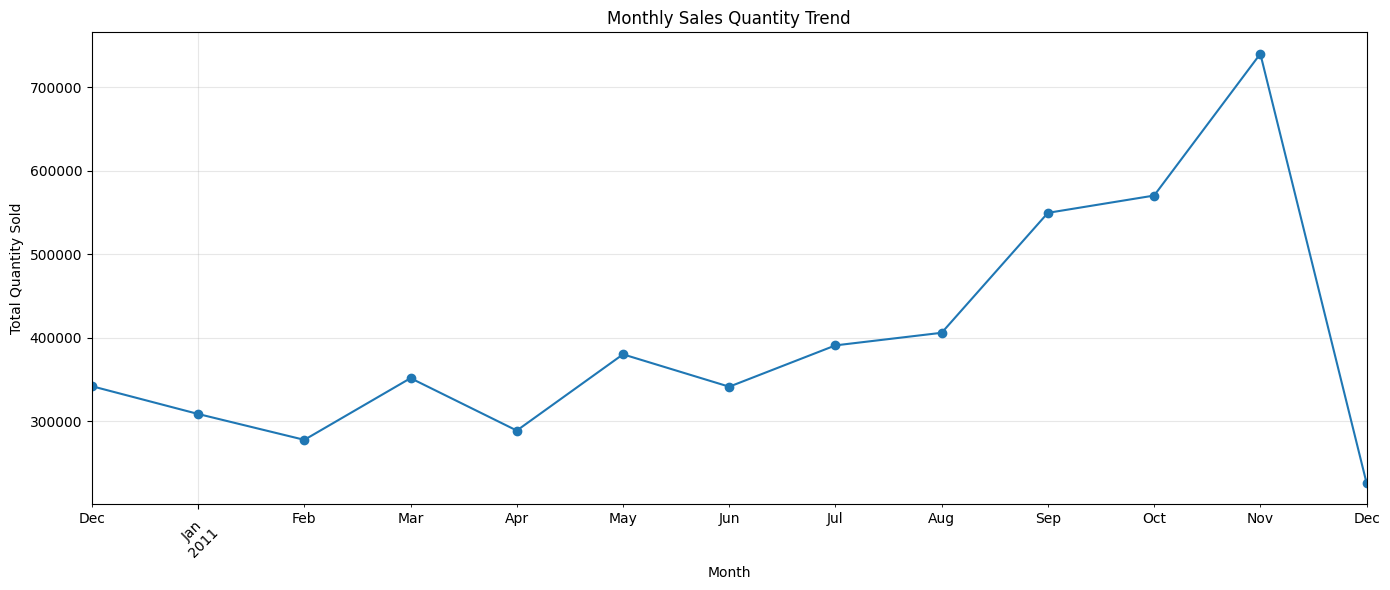

In [32]:
plt.figure(figsize=(14, 6))

monthly_quantity.plot(kind='line', marker='o')

plt.title('Monthly Sales Quantity Trend')
plt.xlabel('Month')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Sales Quantity Insights

- Sales quantity fluctuated during the first eight months of the observed period.
- A noticeable increase in sales volume started in September 2011.
- November recorded the highest sales quantity, reaching 740,286 units.
- The increase in sales quantity from September to November coincided with the increase in monthly revenue.
- December 2011 is incomplete, covering only the first nine days of the month.

**Note:** These quantities include negative quantity records, which may represent returns or other adjustments.

In [33]:
monthly_revenue_growth = monthly_revenue.pct_change() * 100

display(monthly_revenue_growth.to_frame(name='Revenue Growth (%)'))

,Revenue Growth (%)
InvoiceDate_dt,
2010-12,NaN
2011-01,-25.229320
2011-02,-11.060282
2011-03,37.184967
2011-04,-27.816350
2011-05,46.659178
2011-06,-4.453048
2011-07,-1.421311
2011-08,0.202612


### Monthly Revenue Growth Insights

- September 2011 recorded the highest month-over-month revenue growth at approximately 49.37%.
- May 2011 also showed strong growth, reaching approximately 46.66%.
- April 2011 recorded the largest revenue decline among complete months, at approximately 27.82%.
- Revenue remained relatively stable between June and August.
- Strong positive growth occurred in September and November.
- December's negative growth rate is not directly comparable because the dataset only covers the first nine days of the month.

**Note:** Growth rates are calculated using the previous month's recorded line total. December 2011 is excluded from meaningful month-over-month performance comparisons due to incomplete data.

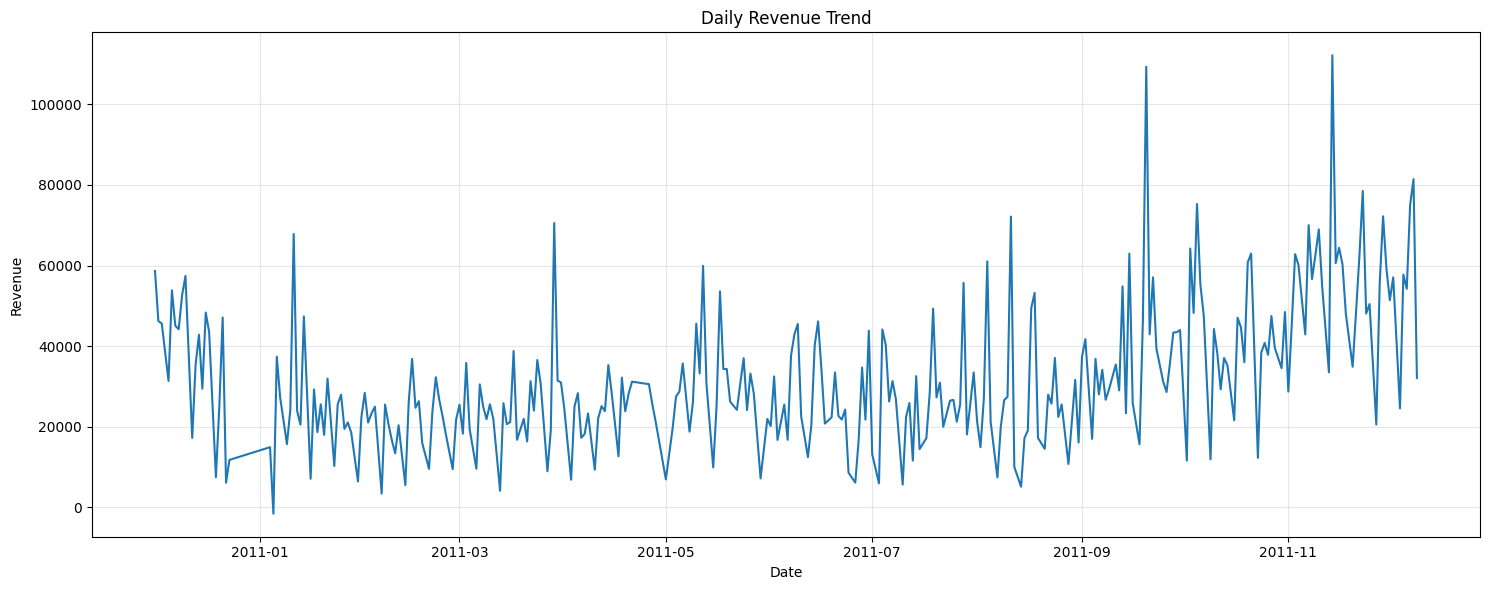

In [34]:
daily_revenue = (
    x.groupby(x['InvoiceDate_dt'].dt.date)['LineTotal']
    .sum()
)

plt.figure(figsize=(15, 6))

daily_revenue.plot()

plt.title('Daily Revenue Trend')
plt.xlabel('Date')
plt.ylabel('Revenue')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
daily_revenue_df = daily_revenue.copy()

daily_revenue_df.index = pd.to_datetime(daily_revenue_df.index)

daily_revenue_df.index.name = 'Date'

daily_revenue_df = daily_revenue_df.reset_index()

daily_revenue_df['DayOfWeek'] = daily_revenue_df['Date'].dt.day_name()

weekday_avg_revenue = (
    daily_revenue_df.groupby('DayOfWeek')['LineTotal']
    .mean()
)

In [36]:
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekday_avg_revenue = weekday_avg_revenue.reindex(weekday_order)

display(weekday_avg_revenue.to_frame(name='Average Daily Revenue'))

,Average Daily Revenue
DayOfWeek,
Monday,33800.200660
Tuesday,37811.207519
Wednesday,32719.754906
Thursday,39858.849057
Friday,30812.216220
Saturday,NaN
Sunday,16113.577820


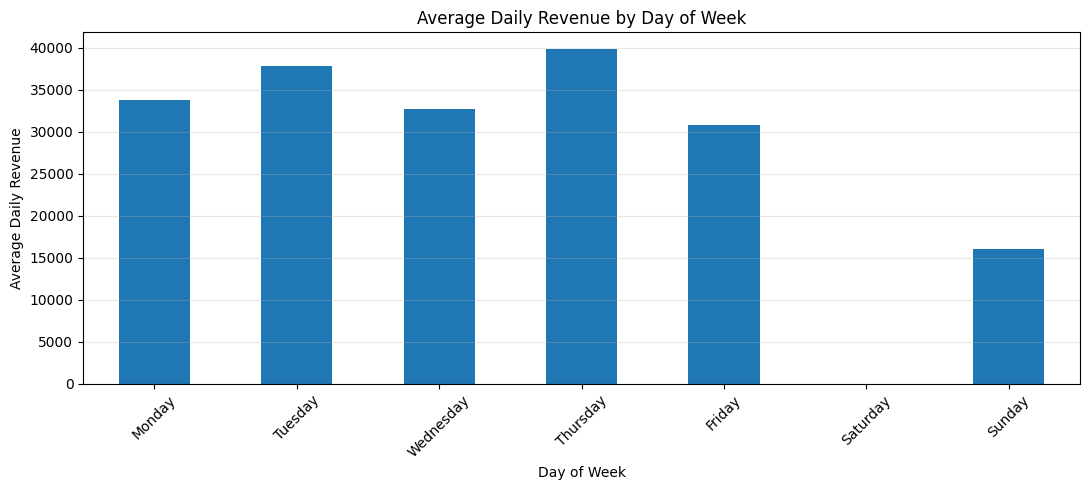

In [37]:
plt.figure(figsize=(11, 5))

weekday_avg_revenue.plot(kind='bar')

plt.title('Average Daily Revenue by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Daily Revenue')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Day-of-Week Revenue Insights

- Thursday recorded the highest average daily revenue, at approximately 39,859.
- Sunday recorded the lowest average daily revenue among the observed weekdays, at approximately 16,114.
- Tuesday also showed relatively strong average daily revenue.
- No Saturday records were found in the dataset.
- Revenue varied across weekdays, suggesting potential differences in daily sales activity.

**Note:** These are descriptive observations. The number of observations per weekday should be considered before drawing conclusions.

In [38]:
daily_revenue_df['DayOfWeek'].value_counts().reindex(weekday_order, fill_value=0)

,count
DayOfWeek,
Monday,47
Tuesday,52
Wednesday,53
Thursday,53
Friday,50
Saturday,0
Sunday,50


In [39]:
x['Hour'] = x['InvoiceDate_dt'].dt.hour

hourly_revenue = (
    x.groupby('Hour')['LineTotal']
    .sum()
)

display(hourly_revenue.to_frame(name='Total Revenue'))

,Total Revenue
Hour,
6,-497.350
7,31009.320
8,281840.860
9,766734.051
10,1329056.521
11,1147437.920
12,1362484.290
13,1177506.370
14,1095212.901


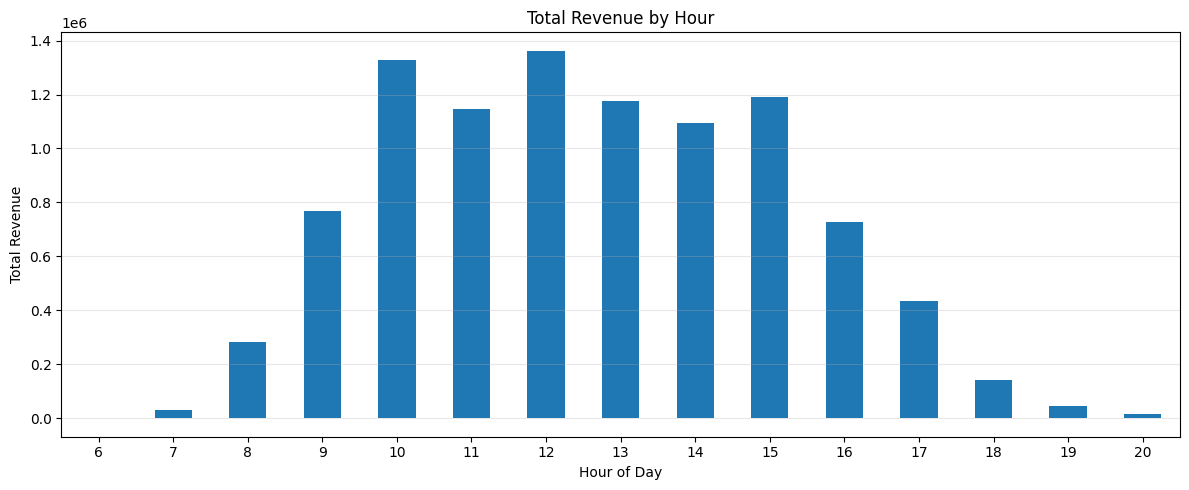

In [40]:
plt.figure(figsize=(12, 5))

hourly_revenue.plot(kind='bar')

plt.title('Total Revenue by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Total Revenue')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Hourly Revenue Insights

- Revenue activity increased significantly from 8 AM onward.
- The highest recorded hourly revenue occurred at 12 PM, reaching approximately 1.36 million.
- The period from 10 AM to 3 PM showed consistently high revenue activity.
- Revenue declined noticeably after 3 PM.
- Very limited revenue activity was observed during the evening hours.
- A small negative recorded value appeared at 6 AM, potentially reflecting returns or adjustments.

**Note:** These values represent total recorded line values grouped by transaction hour, including negative quantities.

In [42]:
country_records = (
    x['Country']
    .value_counts()
    .head(10)
)

display(country_records.to_frame(name='Transaction Rows'))

,Transaction Rows
Country,
United Kingdom,495478
Germany,9495
France,8557
EIRE,8196
Spain,2533
Netherlands,2371
Belgium,2069
Switzerland,2002
Portugal,1519


In [43]:
country_revenue = (
    x.groupby('Country')['LineTotal']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_revenue.to_frame(name='Total Revenue'))

,Total Revenue
Country,
United Kingdom,8187806.364
Netherlands,284661.540
EIRE,263276.820
Germany,221698.210
France,197403.900
Australia,137077.270
Switzerland,56385.350
Spain,54774.580
Belgium,40910.960


In [44]:
country_quantity = (
    x.groupby('Country')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(country_quantity.to_frame(name='Total Quantity'))

,Total Quantity
Country,
United Kingdom,4263829
Netherlands,200128
EIRE,142637
Germany,117448
France,110480
Australia,83653
Sweden,35637
Switzerland,30325
Spain,26824


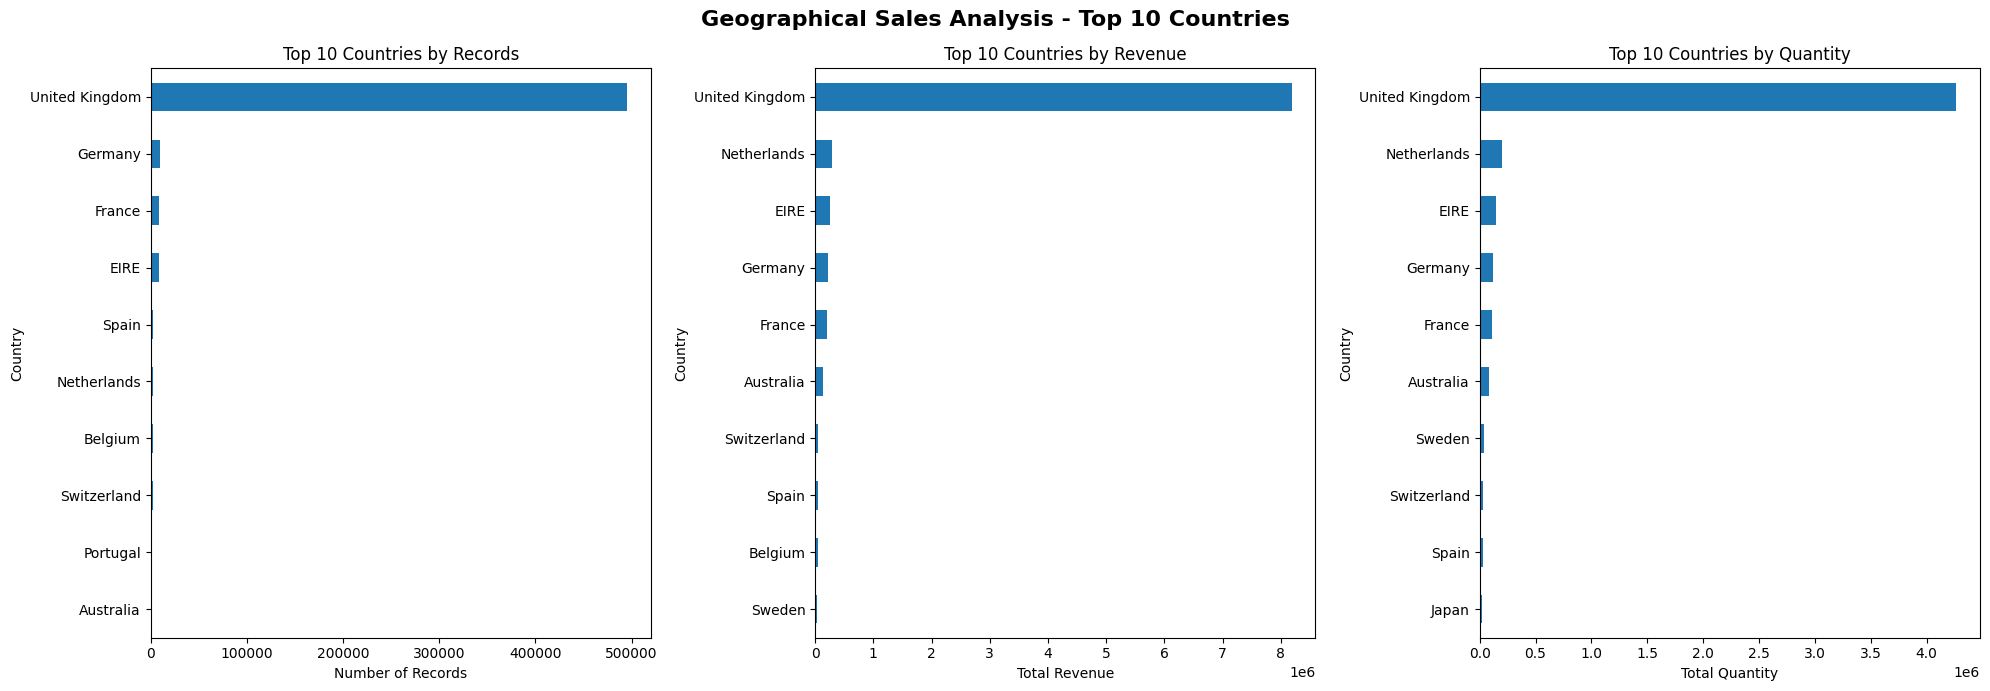

In [47]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# 1. Number of transaction rows
country_records.plot(
    kind='barh',
    ax=axes[0]
)
axes[0].set_title('Top 10 Countries by Records')
axes[0].set_xlabel('Number of Records')
axes[0].invert_yaxis()

# 2. Total revenue
country_revenue.plot(
    kind='barh',
    ax=axes[1]
)
axes[1].set_title('Top 10 Countries by Revenue')
axes[1].set_xlabel('Total Revenue')
axes[1].invert_yaxis()

# 3. Total quantity
country_quantity.plot(
    kind='barh',
    ax=axes[2]
)
axes[2].set_title('Top 10 Countries by Quantity')
axes[2].set_xlabel('Total Quantity')
axes[2].invert_yaxis()

fig.suptitle(
    'Geographical Sales Analysis - Top 10 Countries',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [48]:
country_summary = pd.DataFrame({
    'Transaction_Rows': x['Country'].value_counts(),
    'Total_Quantity': x.groupby('Country')['Quantity'].sum()
})

country_summary['Quantity_Percentage'] = (
    country_summary['Total_Quantity'] /
    country_summary['Total_Quantity'].sum()
) * 100

country_summary['Records_Percentage'] = (
    country_summary['Transaction_Rows'] /
    country_summary['Transaction_Rows'].sum()
) * 100

country_summary.sort_values(
    'Total_Quantity',
    ascending=False
).head(10).round(2)

,Transaction_Rows,Total_Quantity,Quantity_Percentage,Records_Percentage
Country,,,,
United Kingdom,495478,4263829,82.37,91.43
Netherlands,2371,200128,3.87,0.44
EIRE,8196,142637,2.76,1.51
Germany,9495,117448,2.27,1.75
France,8557,110480,2.13,1.58
Australia,1259,83653,1.62,0.23
Sweden,462,35637,0.69,0.09
Switzerland,2002,30325,0.59,0.37
Spain,2533,26824,0.52,0.47


In [49]:
country_summary['Avg_Quantity_Per_Record'] = (
    country_summary['Total_Quantity'] /
    country_summary['Transaction_Rows']
)

country_summary.sort_values(
    'Avg_Quantity_Per_Record',
    ascending=False
).head(10).round(2)

,Transaction_Rows,Total_Quantity,Quantity_Percentage,Records_Percentage,Avg_Quantity_Per_Record
Country,,,,,
Netherlands,2371,200128,3.87,0.44,84.41
Sweden,462,35637,0.69,0.09,77.14
Japan,358,25218,0.49,0.07,70.44
Australia,1259,83653,1.62,0.23,66.44
Singapore,229,5234,0.10,0.04,22.86
Denmark,389,8188,0.16,0.07,21.05
Czech Republic,30,592,0.01,0.01,19.73
Lithuania,35,652,0.01,0.01,18.63
Canada,151,2763,0.05,0.03,18.30


### Geographical Sales Analysis Insights

- The United Kingdom dominates the dataset, accounting for 91.43% of transaction records and 82.37% of total quantity sold.
- The Netherlands ranks second in total quantity, contributing 3.87%, despite representing only 0.44% of transaction records.
- Germany, France, and EIRE have more transaction records than the Netherlands, but lower total quantities.
- The differences between record percentages and quantity percentages suggest variations in the average quantity recorded per product line across countries.
- Sales activity is highly concentrated in the United Kingdom, while the remaining countries contribute relatively small shares.

**Note:** Transaction records represent product-line rows, not unique invoices or orders. The analysis uses the available country and quantity fields.

In [50]:
x['UnitPrice'].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
)

,UnitPrice
count,541909.000000
mean,4.611114
std,96.759853
min,-11062.060000
1%,0.190000
5%,0.420000
25%,1.250000
50%,2.080000
75%,4.130000
95%,9.950000


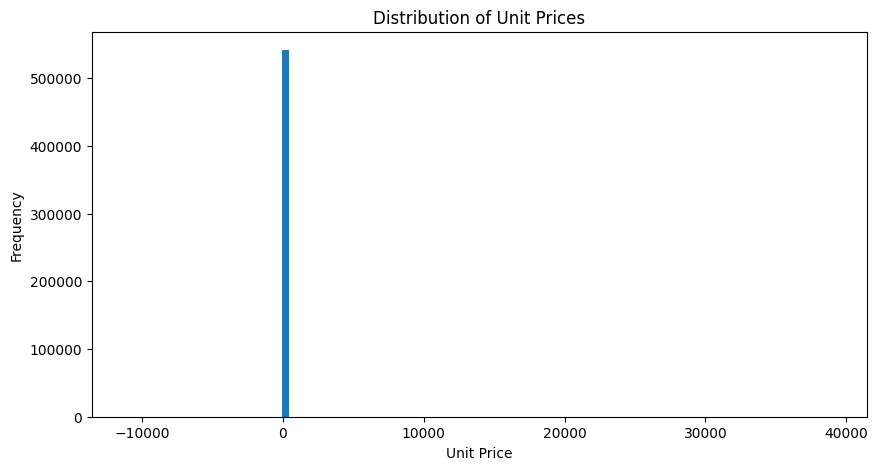

In [51]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(x['UnitPrice'], bins=100)

plt.title('Distribution of Unit Prices')
plt.xlabel('Unit Price')
plt.ylabel('Frequency')

plt.show()

In [52]:
# Count unusual unit prices

price_counts = {
    'Negative Prices': (x['UnitPrice'] < 0).sum(),
    'Zero Prices': (x['UnitPrice'] == 0).sum(),
    'Positive Prices': (x['UnitPrice'] > 0).sum(),
    'Prices Above 99th Percentile': (x['UnitPrice'] > 18).sum()
}

pd.Series(price_counts)

,0
Negative Prices,2
Zero Prices,2515
Positive Prices,539392
Prices Above 99th Percentile,4790


In [53]:
# Inspect negative prices

negative_price_rows = x[
    x['UnitPrice'] < 0
].sort_values('UnitPrice')

negative_price_rows[
    ['Description', 'Quantity', 'UnitPrice',
     'CustomerID', 'Country']
].head(15)

,Description,Quantity,UnitPrice,CustomerID,Country
299983,Adjust bad debt,1,-11062.06,NaN,United Kingdom
299984,Adjust bad debt,1,-11062.06,NaN,United Kingdom


In [54]:
# Inspect the highest unit prices

highest_price_rows = x.nlargest(
    15, 'UnitPrice'
)

highest_price_rows[
    ['Description', 'Quantity', 'UnitPrice',
     'CustomerID', 'Country']
]

,Description,Quantity,UnitPrice,CustomerID,Country
222681,Manual,-1,38970.00,15098.0,United Kingdom
524602,AMAZON FEE,-1,17836.46,NaN,United Kingdom
43702,AMAZON FEE,-1,16888.02,NaN,United Kingdom
43703,AMAZON FEE,-1,16453.71,NaN,United Kingdom
15016,AMAZON FEE,-1,13541.33,NaN,United Kingdom
15017,AMAZON FEE,1,13541.33,NaN,United Kingdom
16356,AMAZON FEE,-1,13541.33,NaN,United Kingdom
16232,AMAZON FEE,-1,13474.79,NaN,United Kingdom
524601,AMAZON FEE,-1,11586.50,NaN,United Kingdom
299982,Adjust bad debt,1,11062.06,NaN,United Kingdom


In [55]:
zero_price_rows = x[x['UnitPrice'] == 0]

print("Zero-price rows:", len(zero_price_rows))
print("Unique descriptions:", zero_price_rows['Description'].nunique())

zero_price_rows['Description'].value_counts().head(15)

Zero-price rows: 2515
Unique descriptions: 376


,count
Description,
check,159
?,47
damages,45
damaged,43
found,25
sold as set on dotcom,20
adjustment,16
Damaged,14
"Unsaleable, destroyed.",9


In [56]:
high_price_rows = x[x['UnitPrice'] > 18]

print("High-price rows:", len(high_price_rows))

high_price_rows['Description'].value_counts().head(15)

High-price rows: 4790


,count
Description,
DOTCOM POSTAGE,692
POSTAGE,288
REGENCY CAKESTAND 3 TIER,247
Manual,243
PICNIC BASKET WICKER LARGE,186
SET/4 WHITE RETRO STORAGE CUBES,163
CARRIAGE,140
ENAMEL BREAD BIN CREAM,120
RED RETROSPOT CAKE STAND,97


In [57]:
x.nlargest(30, 'UnitPrice')[
    ['Description', 'Quantity', 'UnitPrice', 'Country']
]

,Description,Quantity,UnitPrice,Country
222681,Manual,-1,38970.00,United Kingdom
524602,AMAZON FEE,-1,17836.46,United Kingdom
43702,AMAZON FEE,-1,16888.02,United Kingdom
43703,AMAZON FEE,-1,16453.71,United Kingdom
15016,AMAZON FEE,-1,13541.33,United Kingdom
15017,AMAZON FEE,1,13541.33,United Kingdom
16356,AMAZON FEE,-1,13541.33,United Kingdom
16232,AMAZON FEE,-1,13474.79,United Kingdom
524601,AMAZON FEE,-1,11586.50,United Kingdom
299982,Adjust bad debt,1,11062.06,United Kingdom


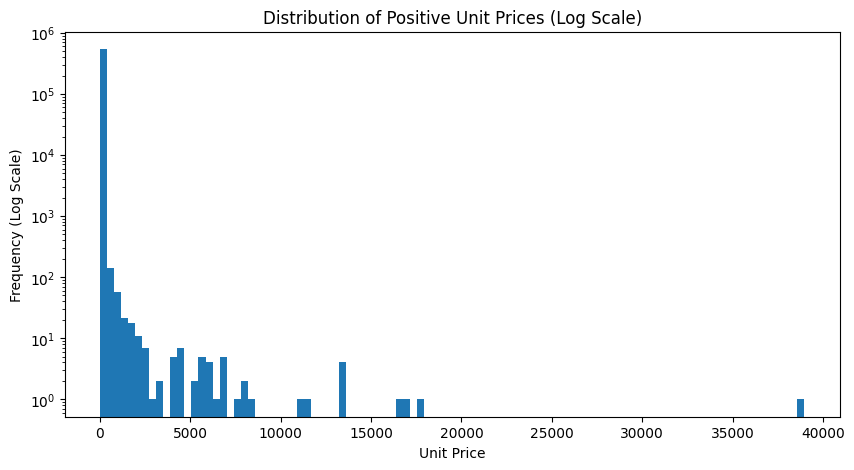

In [58]:
# Select positive unit prices for price distribution analysis

positive_prices = x.loc[
    x['UnitPrice'] > 0,
    'UnitPrice'
]

plt.figure(figsize=(10, 5))

plt.hist(positive_prices, bins=100)

plt.yscale('log')

plt.title('Distribution of Positive Unit Prices (Log Scale)')
plt.xlabel('Unit Price')
plt.ylabel('Frequency (Log Scale)')

plt.show()

# Final Exploratory Data Analysis Summary

## 1. Dataset Overview

- The dataset contains 541,909 records and 6 available features.
- It covers transactions from December 2010 to December 2011.
- The dataset includes product descriptions, quantities, unit prices, invoice dates, customer IDs, and countries.

## 2. Data Quality Findings

- `CustomerID` contains 135,080 missing values (approximately 24.93%).
- `Description` contains 1,454 missing values.
- `UnitPrice` includes 2 negative values and 2,515 zero-price records.
- The dataset contains unusually high unit prices, including special records such as fees, postage, and manual adjustments.
- Missing and unusual values require context-aware treatment rather than automatic deletion.

## 3. Customer Analysis

- The dataset contains 4,372 unique identified customers.
- Customer activity is highly right-skewed: a relatively small number of customers account for many records.
- Customers with the highest record counts are not necessarily the highest-spending customers.
- Customer spending was calculated using the sum of line totals, including negative quantities.

## 4. Product Analysis

- The analysis identified 4,077 unique product descriptions.
- `PAPER CRAFT, LITTLE BIRDIE` ranked first by total quantity sold.
- `DOTCOM POSTAGE` ranked first by recorded line revenue, highlighting the importance of distinguishing products from service-related entries.
- A total of 424 product descriptions (10.4%) recorded sales of 10 units or fewer.
- Quantity sold and revenue rankings differ because products have different unit prices.

## 5. Time-Based Analysis

- Monthly revenue and quantity both increased noticeably during September–November 2011.
- November recorded the highest monthly revenue and quantity.
- December 2011 is incomplete, as the dataset ends on December 9.
- The highest hourly recorded revenue occurred at 12 PM.
- Thursday had the highest average daily revenue among observed weekdays.
- These patterns describe the available records and should not be interpreted as definitive seasonal behavior.

## 6. Geographical Analysis

- The United Kingdom accounts for 91.43% of transaction records and 82.37% of total quantity.
- The Netherlands ranks second by total quantity, despite representing only 0.44% of records.
- Differences between record percentages and quantity percentages indicate variations in average quantity per product-line record across countries.
- Sales activity is heavily concentrated in the United Kingdom.

## 7. Unit Price Analysis

- Unit prices are strongly right-skewed.
- The mean unit price is 4.61, while the median is 2.08.
- The 99th percentile is 18.00, while the maximum reaches 38,970.
- Extremely high values include special entries such as `AMAZON FEE`, `POSTAGE`, and `Manual`.
- Negative and zero prices require separate investigation before being used in product price analysis.

## 8. Key Limitations

- The available dataset version does not include `InvoiceNo` or `StockCode`.
- Therefore, invoice-level analysis, purchase frequency, cancellation identification, and reliable product-code-based grouping could not be performed.
- Grouping by product description may treat differently written descriptions of the same product as separate items.
- Some revenue calculations include negative quantities and special accounting or service-related records.
- The dataset covers approximately one year, with December 2011 only partially represented.

## 9. Conclusion

The EDA revealed customer, product, temporal, geographical, and pricing patterns in the Online Retail dataset.

It also demonstrated why understanding the business context of unusual values is essential before cleaning or transforming data.

The findings provide a foundation for further analysis, while the identified limitations should guide any future modeling or preprocessing work.